# ARTI403: Image Processing
## Lab 3: Image Manipulations using OpenCV

**Student Name:** Saad Abdulaziz Alshehri  
**Student ID:** 2240006495


## Step 1: Read an image

(512, 512, 3)
uint8


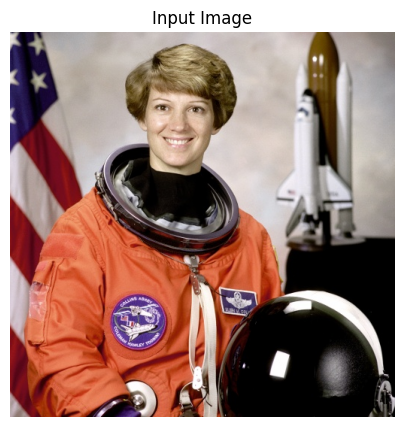

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

os.makedirs('images', exist_ok=True)

# save the astronaut image from skimage as input.jpg
cv2.imwrite('images/input.jpg', cv2.cvtColor(data.astronaut(), cv2.COLOR_RGB2BGR))

img = cv2.imread('images/input.jpg')
print(img.shape)
print(img.dtype)

def show(image, title):
    plt.figure(figsize=(5, 5))
    if len(image.shape) == 2:
        plt.imshow(image, cmap='gray')
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis('off')
    plt.show()

show(img, 'Input Image')

## Steps 2 to 4: grayscale, saving and the YUV color space

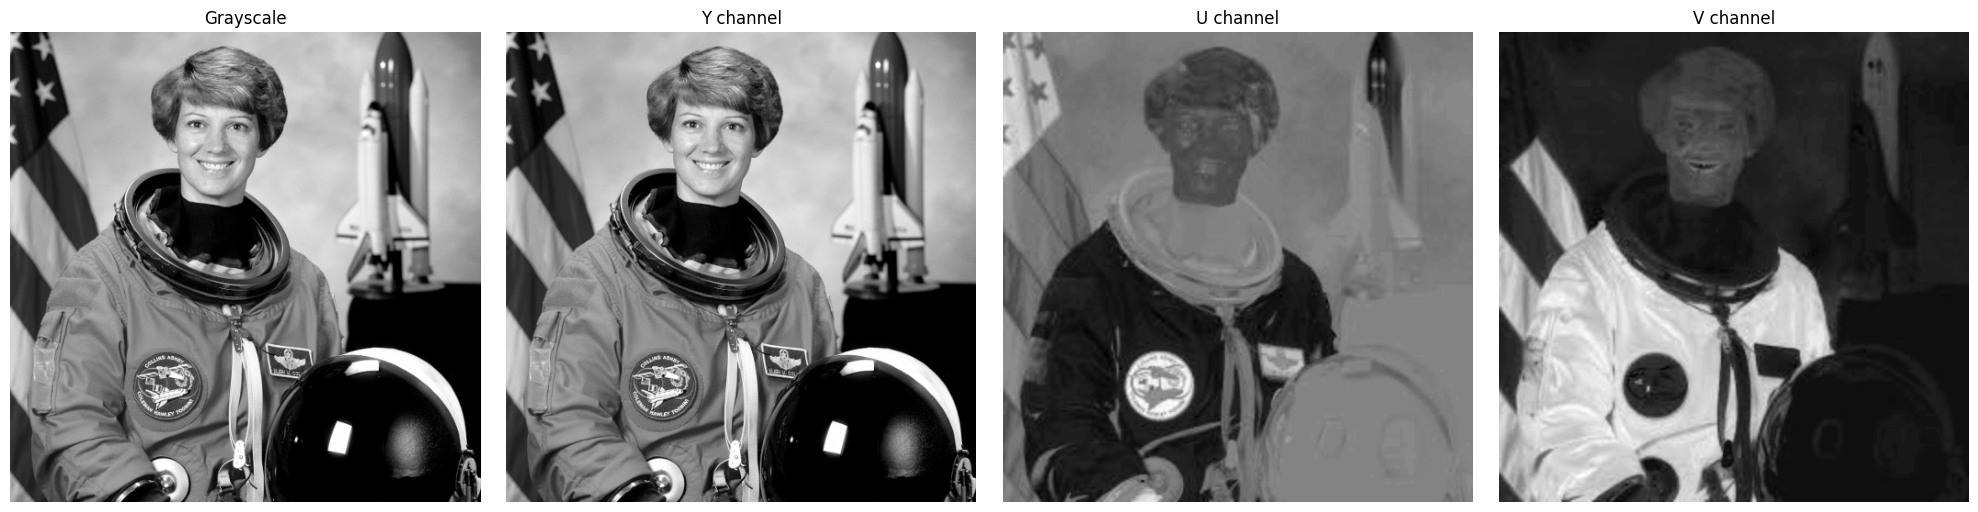

In [2]:
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
cv2.imwrite('images/output.jpg', gray_img)

yuv_img = cv2.cvtColor(img, cv2.COLOR_BGR2YUV)

fig, axs = plt.subplots(1, 4, figsize=(20, 5))
for ax, im, t in zip(axs, [gray_img, yuv_img[:, :, 0], yuv_img[:, :, 1], yuv_img[:, :, 2]],
                     ['Grayscale', 'Y channel', 'U channel', 'V channel']):
    ax.imshow(im, cmap='gray')
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()

# Assessment
## Task 1: Geometric transformations

### Increase the size of the image

(512, 512) -> (768, 768)


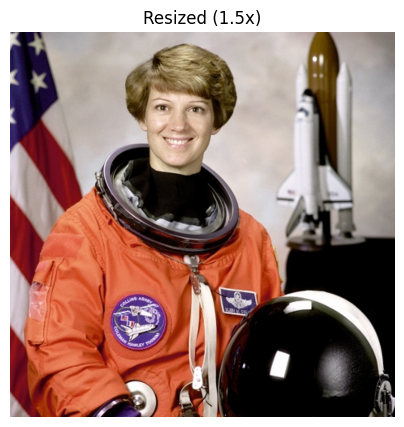

In [3]:
resized = cv2.resize(img, None, fx=1.5, fy=1.5, interpolation=cv2.INTER_CUBIC)
print(img.shape[:2], '->', resized.shape[:2])

cv2.imwrite('images/task1_resized.jpg', resized)
show(resized, 'Resized (1.5x)')

### Rotate the image by 120 degrees

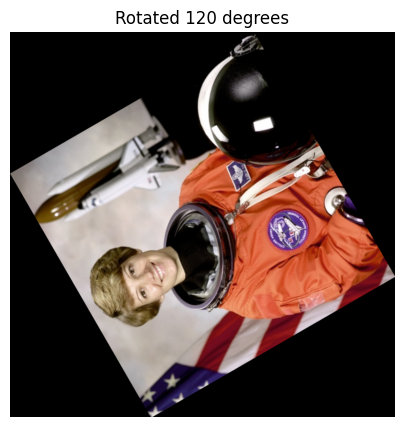

In [4]:
(h, w) = img.shape[:2]
center = (w // 2, h // 2)
M_rotate = cv2.getRotationMatrix2D(center, 120, 1.0)

# new size so the corners are not cut
cos = np.abs(M_rotate[0, 0])
sin = np.abs(M_rotate[0, 1])
new_w = int(h * sin + w * cos)
new_h = int(h * cos + w * sin)
M_rotate[0, 2] += new_w / 2 - center[0]
M_rotate[1, 2] += new_h / 2 - center[1]

rotated = cv2.warpAffine(img, M_rotate, (new_w, new_h))

cv2.imwrite('images/task1_rotated_120.jpg', rotated)
show(rotated, 'Rotated 120 degrees')

### Shear the image

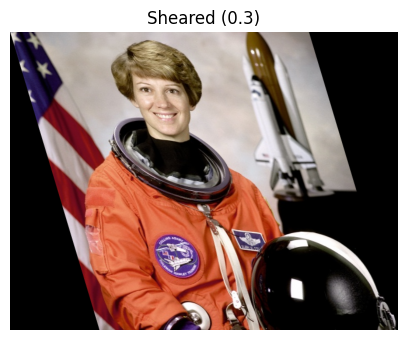

In [5]:
shear_factor = 0.3
M_shear = np.float32([[1, shear_factor, 0],
                      [0, 1, 0]])

# wider output so nothing is cut
new_w = int(w + shear_factor * h)
sheared = cv2.warpAffine(img, M_shear, (new_w, h))

cv2.imwrite('images/task1_sheared.jpg', sheared)
show(sheared, 'Sheared (0.3)')

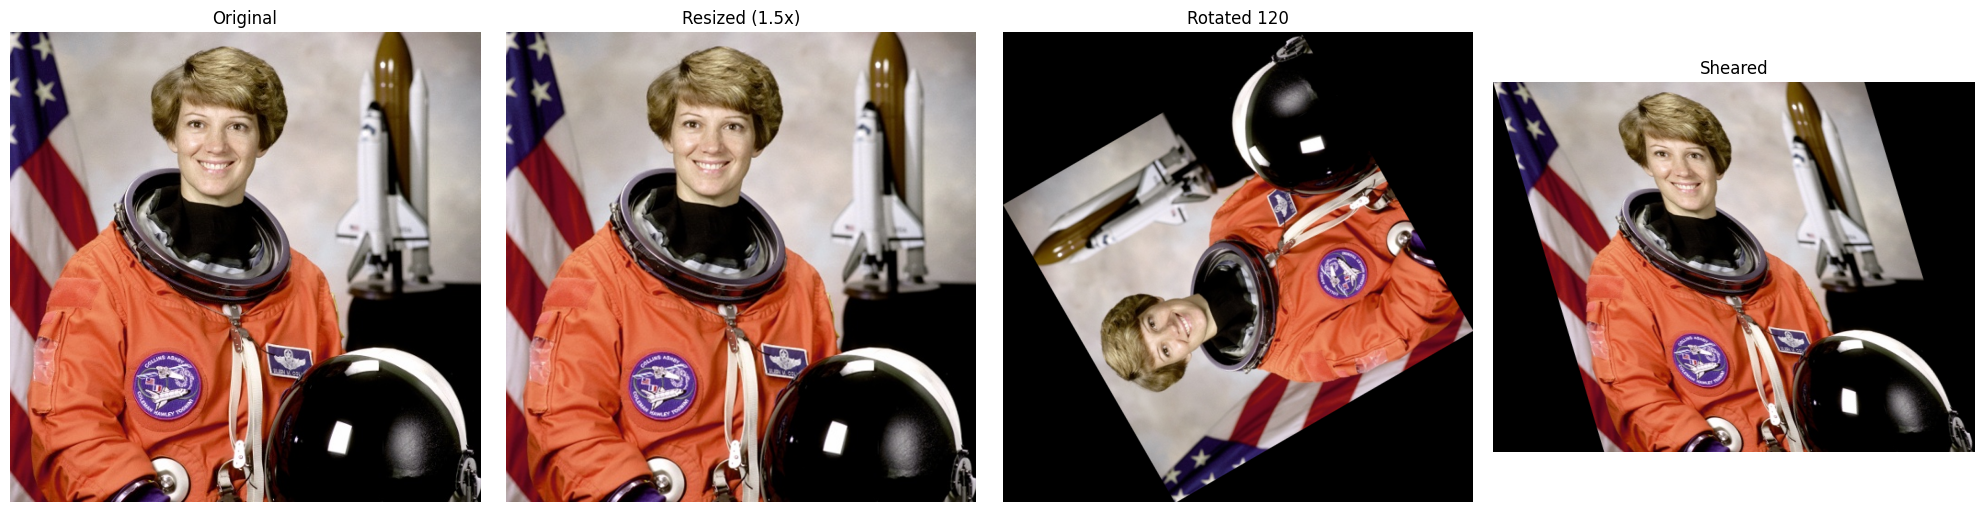

In [6]:
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
for ax, im, t in zip(axs, [img, resized, rotated, sheared],
                     ['Original', 'Resized (1.5x)', 'Rotated 120', 'Sheared']):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.savefig('images/task1_summary.jpg')
plt.show()

## Task 2: Intensity transformations

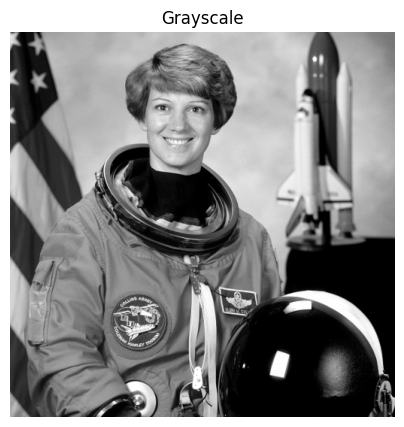

In [7]:
# the intensity transformations are done on the grayscale image
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
show(gray, 'Grayscale')

### Negative image

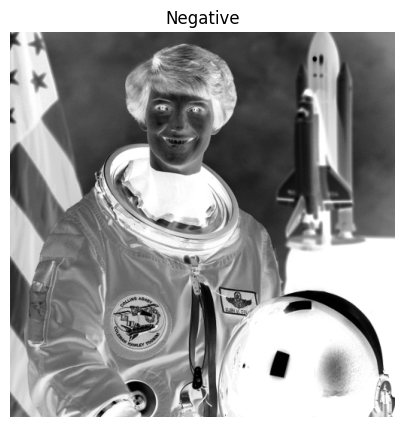

In [8]:
negative = 255 - gray

cv2.imwrite('images/task2_negative.jpg', negative)
show(negative, 'Negative')

### Log transformation

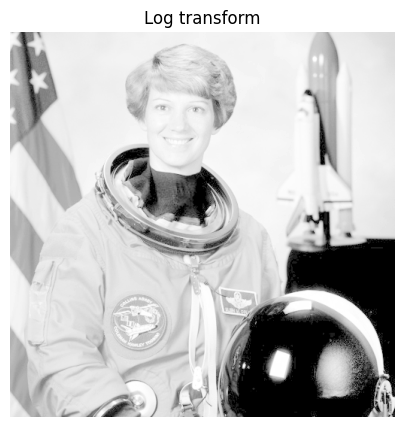

In [9]:
# s = c * log(1 + r), c is chosen so the maximum value becomes 255
c = 255 / np.log(1 + float(np.max(gray)))
log_img = np.array(c * np.log(1 + gray.astype(np.float64)), dtype=np.uint8)

cv2.imwrite('images/task2_log.jpg', log_img)
show(log_img, 'Log transform')

### Power law (gamma) transformation

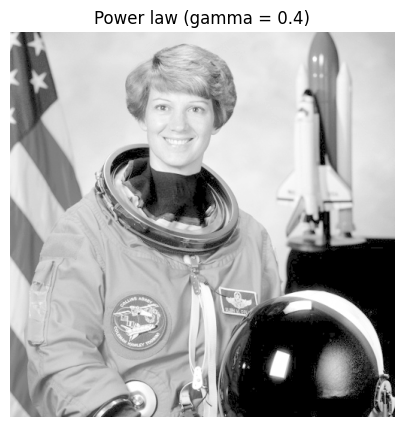

In [10]:
# s = 255 * (r / 255) ** gamma, gamma < 1 makes the dark areas brighter
gamma = 0.4
gamma_img = np.array(255 * (gray / 255.0) ** gamma, dtype=np.uint8)

cv2.imwrite('images/task2_gamma.jpg', gamma_img)
show(gamma_img, 'Power law (gamma = 0.4)')

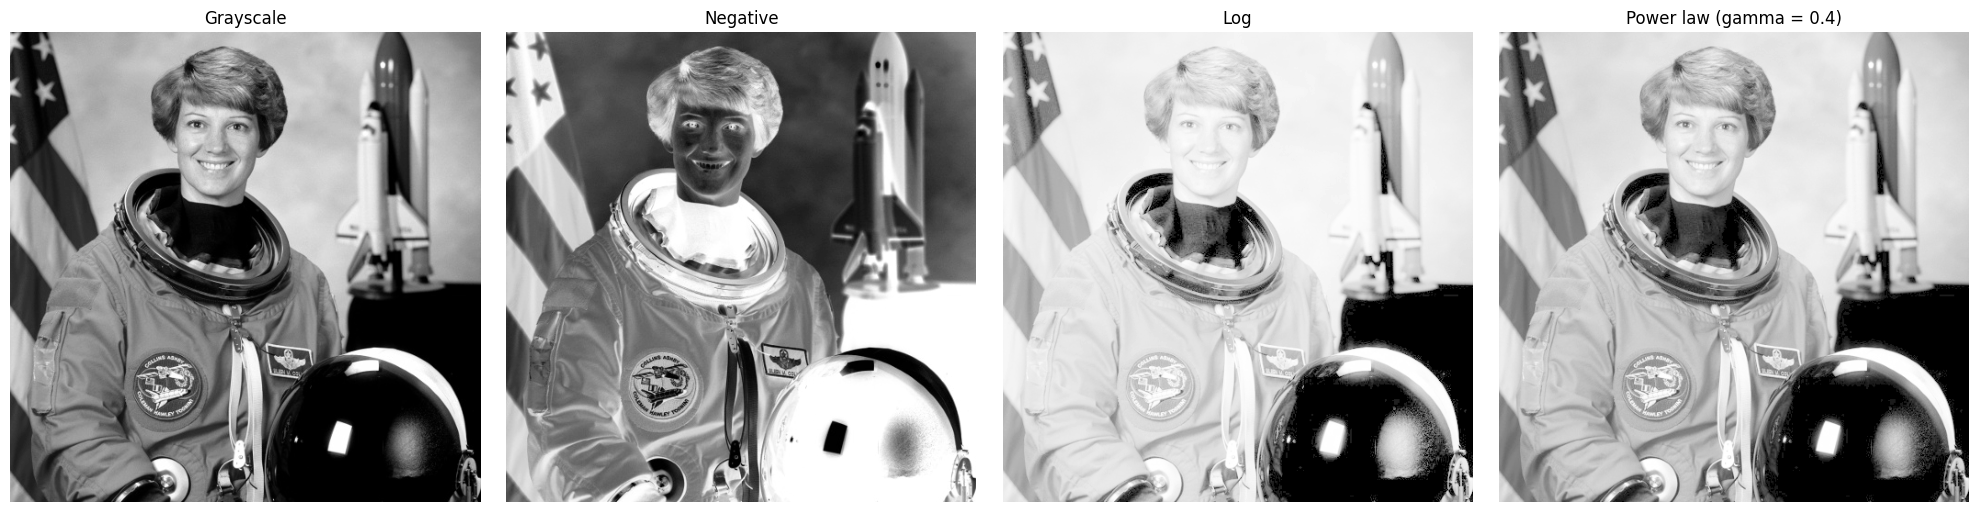

In [11]:
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
for ax, im, t in zip(axs, [gray, negative, log_img, gamma_img],
                     ['Grayscale', 'Negative', 'Log', 'Power law (gamma = 0.4)']):
    ax.imshow(im, cmap='gray')
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.savefig('images/task2_summary.jpg')
plt.show()